## Dataset Selection & Justification

**Dataset:** Predict Students' Dropout and Academic Success

**Source:** UCI Machine Learning Repository
https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

**License:** Creative Commons Attribution 4.0 International (CC BY 4.0)

### Dataset Goal
The dataset is used to predict a student's academic status at the end of the normal course duration: **Dropout**, **Enrolled**, or **Graduate**. In our system, this prediction supports academic advisors and university administrators in identifying at-risk students early, allocating support resources, and designing targeted retention interventions.

### Justification
- **Relevance:** The dataset was collected specifically to study student dropout and academic success in higher education, which aligns directly with our goal of identifying at-risk students. The timing of the available features is discussed in the *Note on Prediction Timing* at the end of the exploratory analysis. Its three-class target supports the multi-class classification required in Phase 1 and provides ground truth for external cluster validation (BCubed) in Phase 2.
- **Completeness:** It contains 4,424 student records and 36 features covering demographic, socioeconomic, macroeconomic, and academic information. This range of attributes allows us to analyze several factors behind student outcomes rather than relying on grades alone. The source reports no missing values.
- **Quality:** The data comes from real institutional records and is published on the UCI Machine Learning Repository, a widely used and curated source. It is structured and tabular, meets the project's size requirements (several hundred rows and at least 10 to 15 features), and can be read directly in Python.

## Initial Data Inspection

This section examines the structure and quality of the student dataset, including its dimensions, data types, missing values, descriptive statistics, and target class distribution.

In [1]:

import pandas as pd
from pathlib import Path
from io import BytesIO

# Search for the dataset in common project locations
paths = [
    Path("Dataset/data.csv"),
    Path("data.csv")
]

dataset_path = next((p for p in paths if p.exists()), None)

if dataset_path:
    df = pd.read_csv(dataset_path, sep=";")
else:
    try:
        from google.colab import files

        print("Upload Dataset/data.csv to continue.")
        uploaded = files.upload()

        if "data.csv" not in uploaded:
            raise FileNotFoundError("Please upload data.csv.")

        df = pd.read_csv(
            BytesIO(uploaded["data.csv"]),
            sep=";"
        )
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found. Make sure Dataset/data.csv is available."
        )

print("Dataset loaded successfully:", df.shape)


Dataset loaded successfully: (4424, 37)


In [2]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of features:", df.shape[1] - 1)

Number of rows: 4424
Number of columns: 37
Number of features: 36


**Dataset Overview**

The dataset contains 4,424 student records and 37 columns, including 36 input features and one target variable. The target variable represents three academic outcomes: Dropout, Enrolled, and Graduate.

In [3]:
# Inspect column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

**Data Types Analysis**

The dataset contains 29 integer columns, 7 floating-point columns, and 1 object column (Target). Most features are stored numerically, although some represent categorical variables encoded as integers.

In [4]:
# Check missing values
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", missing_values.sum())

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

### Missing Values Analysis

The dataset contains no missing values across all 37 columns. This indicates that all 4,424 student records are complete, and no missing-value imputation is required during preprocessing.

In [5]:
# Display descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


**Statistical Summary Analysis**

The dataset contains 4,424 student records. The average age at enrollment is 23.27 years, and the average admission grade is 126.98. The average first-semester grade (10.64) is slightly higher than the second-semester grade (10.23). Some numerical variables represent categorical codes and should not be interpreted as continuous measurements.

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


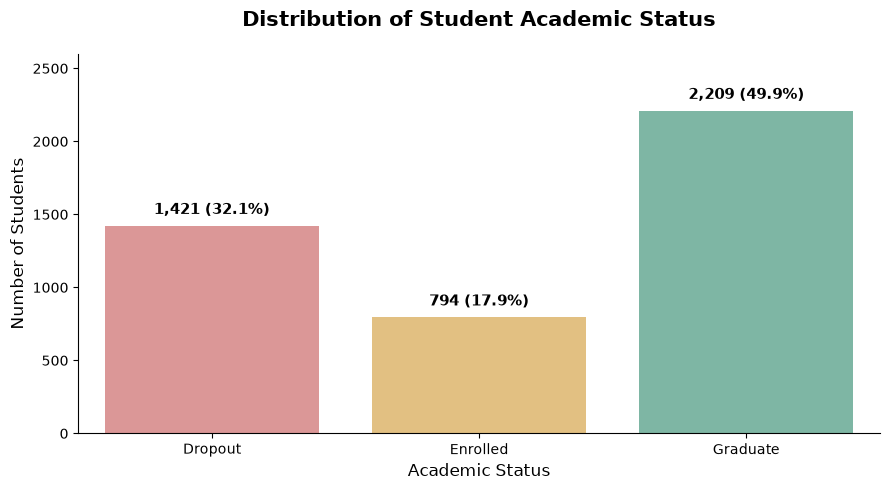

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count students in each academic status
order = ["Dropout", "Enrolled", "Graduate"]
class_counts = df["Target"].value_counts()
print(class_counts)

# Create a professional bar chart
plt.figure(figsize=(9, 5))
colors = ["#E78B8B", "#F2C572", "#75BFA8"]

ax = sns.barplot(
    x=order,
    y=[class_counts[status] for status in order],
    hue=order,
    palette=colors,
    legend=False
)

# Add counts and percentages above bars
total = len(df)

for bar in ax.patches:
    count = int(bar.get_height())
    percentage = count / total * 100
    ax.annotate(
        f"{count:,} ({percentage:.1f}%)",
        (bar.get_x() + bar.get_width()/2, count),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 6),
        textcoords="offset points"
    )

plt.title("Distribution of Student Academic Status",
          fontsize=15, fontweight="bold", pad=20)
plt.xlabel("Academic Status", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)
plt.ylim(0, 2600)
sns.despine()
plt.tight_layout()
plt.show()


**Class Distribution Analysis**

The dataset contains 2,209 graduates, 1,421 dropouts, and 794 enrolled students. Graduates represent the largest class, while enrolled students represent the smallest. This indicates a class imbalance that should be considered during preprocessing and model evaluation.

## Exploratory Data Analysis: Feature Relationships

This section analyzes the relationships between features and the student outcome using histograms, box plots, a correlation heatmap, mutual information, and proportion charts.

### Setup

In [7]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Some original column names contain trailing spaces or tabs, so we clean them.
df.columns = df.columns.str.strip()

# Readable target label column, used only for plotting.
# Works whether the target is stored as text or as codes (0, 1, 2).
target_map = {0: "Dropout", 1: "Enrolled", 2: "Graduate"}
if pd.api.types.is_numeric_dtype(df["Target"]):
    df["Target_label"] = df["Target"].map(target_map)
else:
    df["Target_label"] = df["Target"].astype(str).str.strip()

class_order = ["Dropout", "Enrolled", "Graduate"]
palette = {"Dropout": "#d62728", "Enrolled": "#ff7f0e", "Graduate": "#2ca02c"}

### Feature Groups

Many columns in this dataset are stored as integers but are actually **categorical codes** (for example, `Course`, `Marital status`, and `Application mode`). Treating these codes as numbers would produce misleading histograms and correlations, so we separate the features into groups and choose a suitable plot for each group.

In [8]:
# Continuous / count features: suitable for histograms and box plots
numeric_features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]

# Binary (0/1) features: suitable for proportion bar charts against the target
binary_features = {
    "Tuition fees up to date": {0: "No", 1: "Yes"},
    "Scholarship holder": {0: "No", 1: "Yes"},
    "Debtor": {0: "No", 1: "Yes"},
    "Gender": {0: "Female", 1: "Male"},
    "Displaced": {0: "No", 1: "Yes"},
    "International": {0: "No", 1: "Yes"},
}

# Safety check: confirm every listed column exists in the loaded file
missing = [c for c in numeric_features + list(binary_features) if c not in df.columns]
print("Missing columns:", missing if missing else "none")

Missing columns: none


### 1. Feature Distributions (Histograms)

Histograms show the shape of each numeric feature: whether it is symmetric or skewed, where most values fall, and whether there are unusual spikes.

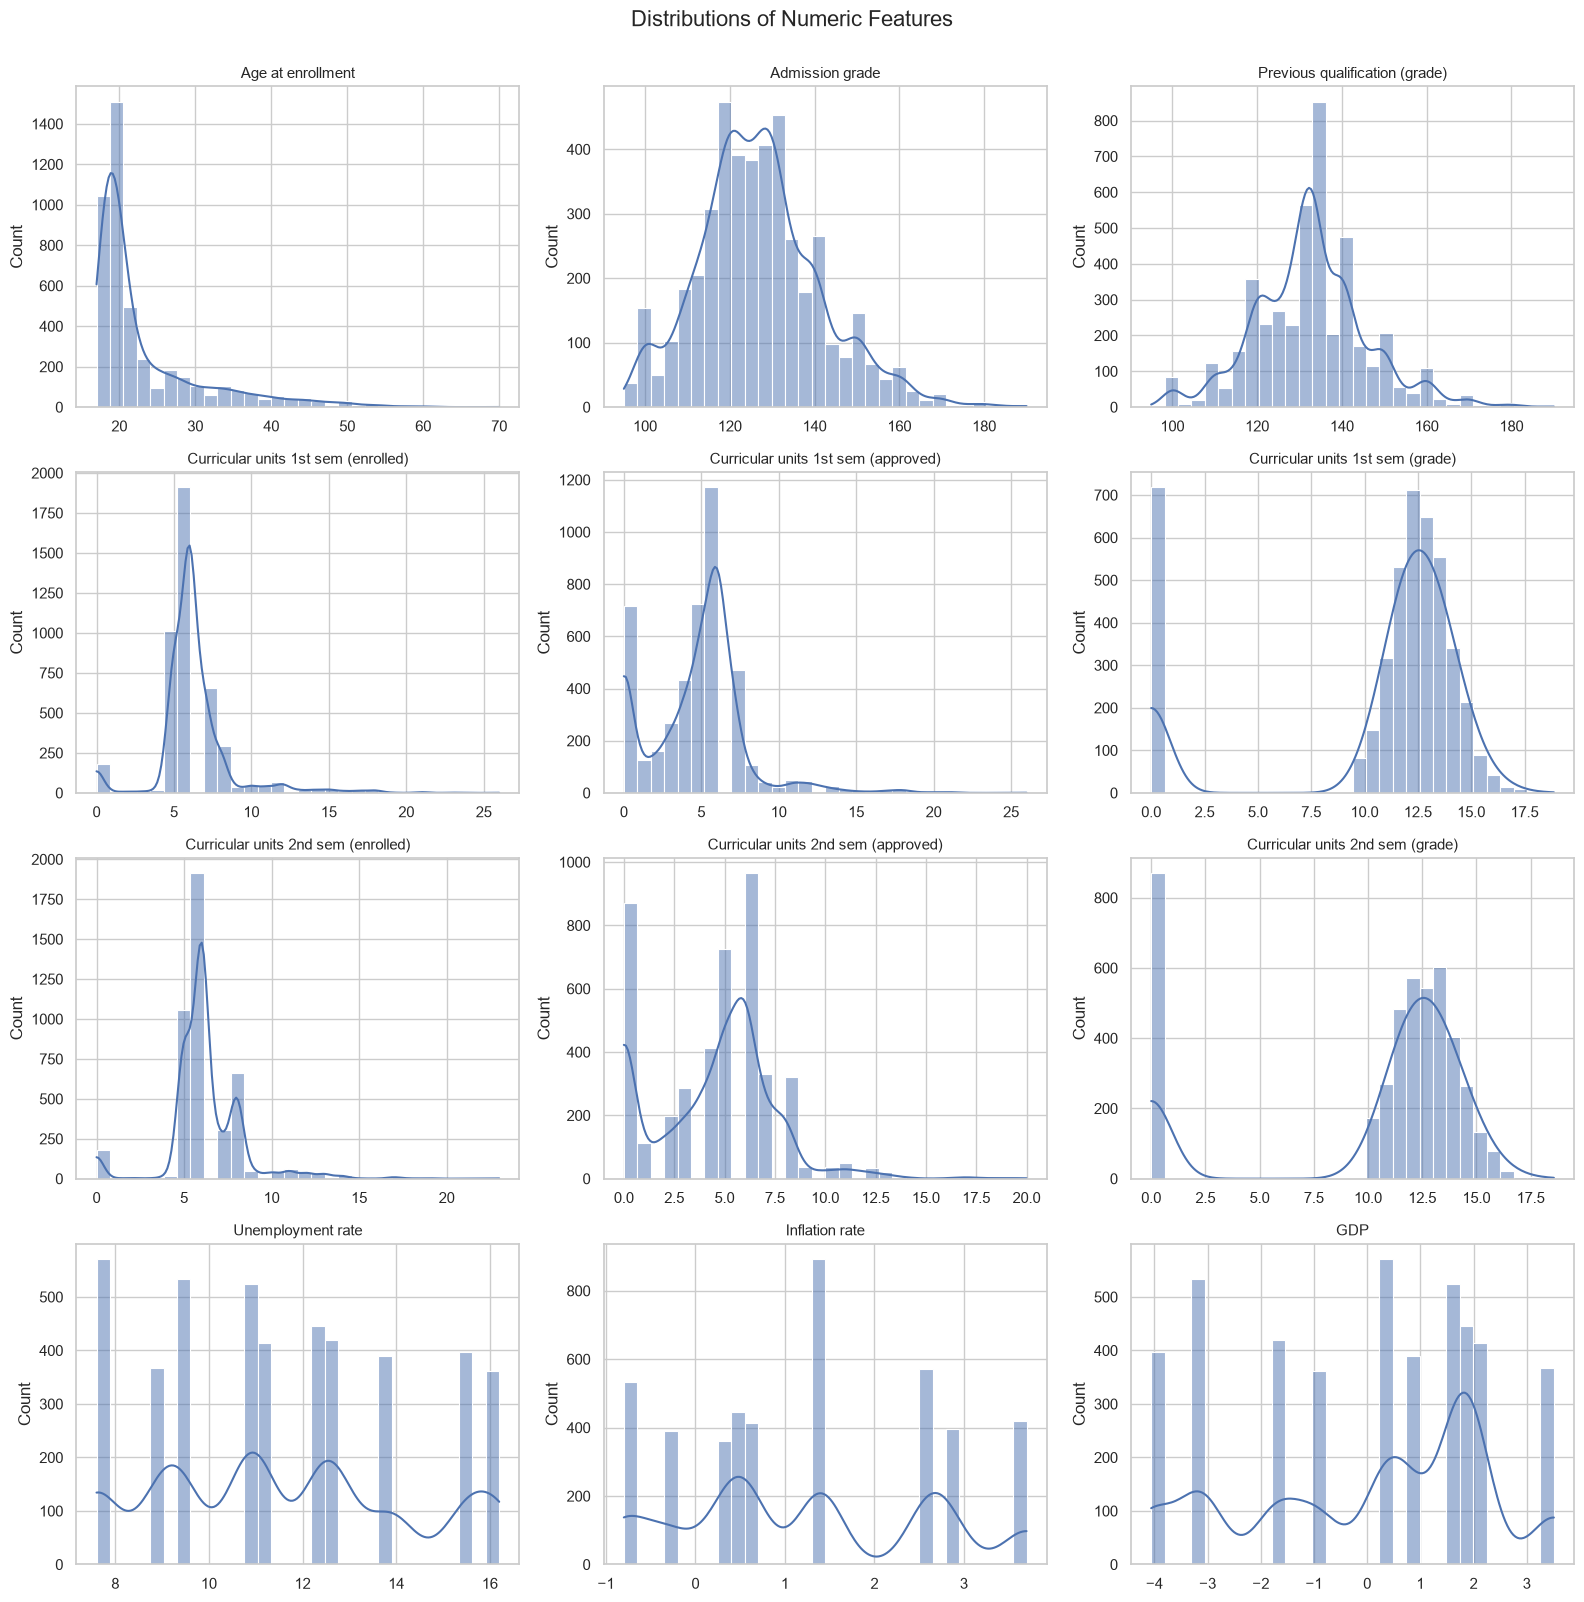

In [9]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, col in zip(axes.flat, numeric_features):
    sns.histplot(df[col], kde=True, bins=30, ax=ax, color="#4c72b0")
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
fig.suptitle("Distributions of Numeric Features", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

**Observations:**
- **Age at enrollment** is strongly right-skewed. The median age is 20, about 76% of students are 25 or younger, and a long tail of older students reaches up to 70.
- **Admission grade** and **Previous qualification (grade)** are roughly bell-shaped, with most students in the middle of the grading scale.
- The **curricular unit grade** features show a noticeable spike at **0**, affecting approximately 16% of students in the 1st semester and 20% in the 2nd semester. Every student with a zero grade has zero approved units in that semester, and every student with zero approved units has a zero grade. This suggests that the grade represents the average of approved units only and is recorded as 0 when no units are approved. Some of these students have recorded evaluations while others do not, so a zero grade does not necessarily mean that the student was not evaluated. These values were retained because they are recorded in the dataset, and their interpretation requires further verification before treating them as missing values or errors.
- **Unemployment rate**, **Inflation rate**, and **GDP** take only 9 to 10 distinct values each, because they describe the economic situation in the student's year of enrollment rather than the individual student.

### 2. Numeric Features by Target Class (Box Plots)

Box plots compare the distribution of each numeric feature across the three outcome classes. Large differences in the median or spread between classes suggest that a feature is associated with the outcome. Points outside the whiskers are potential outliers.

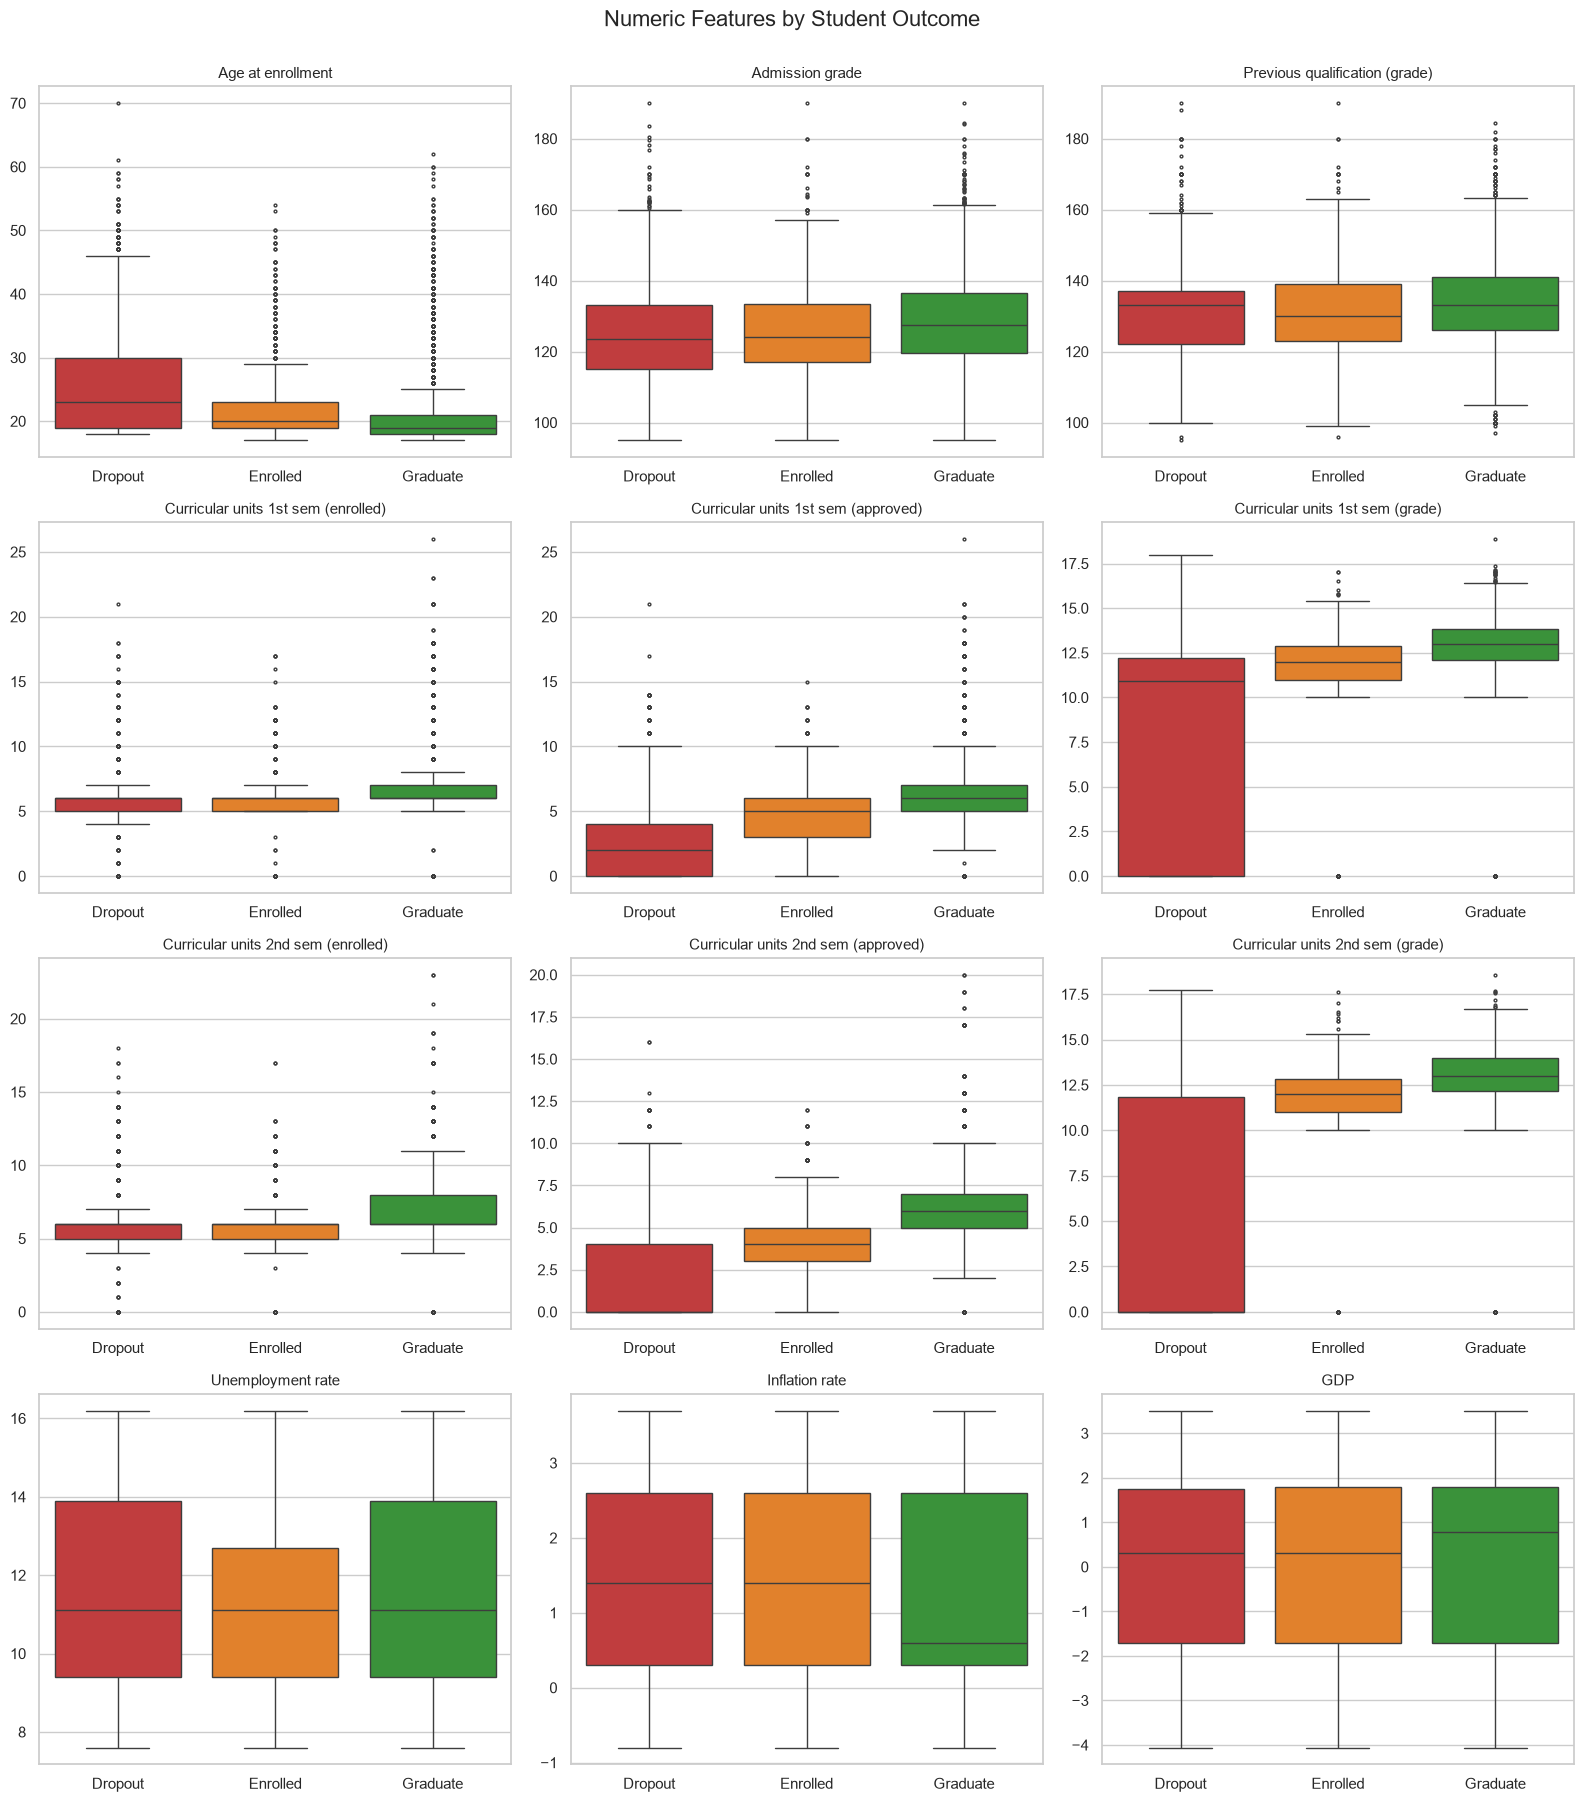

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(16, 18))
for ax, col in zip(axes.flat, numeric_features):
    sns.boxplot(data=df, x="Target_label", y=col, order=class_order,
                palette=palette, ax=ax, fliersize=2)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Numeric Features by Student Outcome", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

**Observations:**
- The **1st and 2nd semester approved units and grades** show the clearest visual separation between classes. For example, the median number of approved units in the 2nd semester is 0 for dropouts, 4 for enrolled students, and 6 for graduates.
- **Dropout** students tend to be **older at enrollment**, with a median age of 23 compared with 19 for graduates.
- **Admission grade** differs only slightly between classes (median of about 124 for dropouts vs. 127 for graduates), and **Previous qualification (grade)** has almost the same median across classes.
- The **Enrolled** class tends to fall between Dropout and Graduate and overlaps with both. This suggests it may be harder to separate, but this must be confirmed with the classification results in Part B.
- Several features contain outliers (for example, very high ages). These are plausible real values, so we keep them rather than removing them.
- These plots show **associations only**. They do not show that a feature causes an outcome or that it predicts the outcome independently of other features.

### 3. Correlation Heatmap (Continuous Features Only)

The heatmap shows the Pearson correlation between the **continuous and count features only**. Two groups of columns are deliberately excluded:

- **The target**, because its classes (Dropout, Enrolled, Graduate) are categories. Encoding them as 0, 1, and 2 would assume equal distances between outcomes, which makes a Pearson correlation with the target misleading.
- **Categorical code columns** (such as `Course`, `Marital status`, and `Application mode`), because their numeric codes have no real order.

The relationship between features and the target is analyzed separately in the box plots, the binary feature charts, and the mutual information analysis.

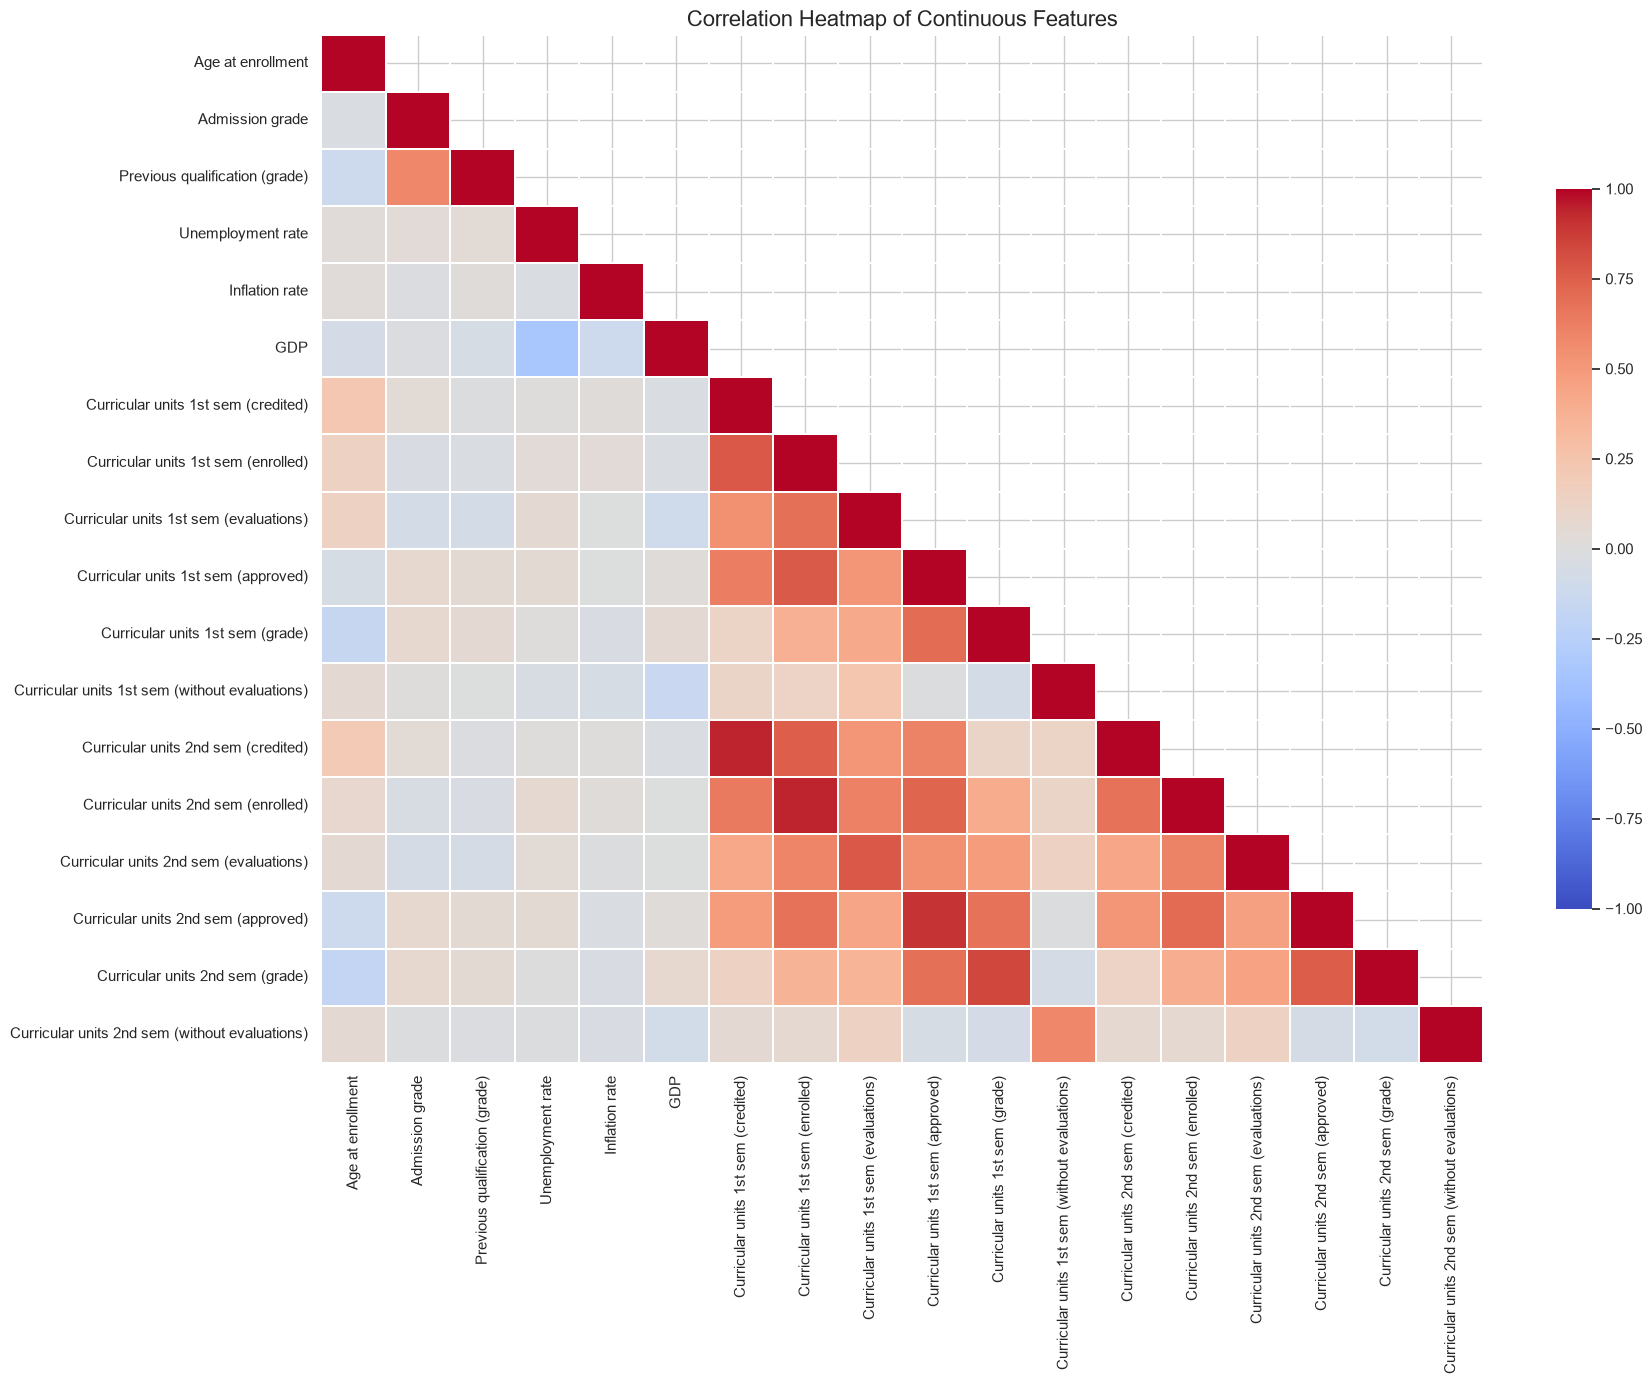

In [11]:
# Continuous and count features only (no target, no categorical codes)
heatmap_features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
] + [
    f"Curricular units {sem} sem ({kind})"
    for sem in ["1st", "2nd"]
    for kind in ["credited", "enrolled", "evaluations", "approved", "grade", "without evaluations"]
]

corr = df[heatmap_features].corr()

plt.figure(figsize=(18, 14))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # hide the duplicate upper triangle
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation Heatmap of Continuous Features", fontsize=16)
plt.tight_layout()
plt.show()

In [12]:
# Highly correlated feature pairs (possible redundancy)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack()
             .reset_index())
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
high_pairs = pairs[pairs["Correlation"].abs() >= 0.8].sort_values("Correlation", ascending=False)
high_pairs.reset_index(drop=True)

,Feature 1,Feature 2,Correlation
0,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.944811
1,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.942627
2,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.904002
3,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.837170


**Observations:**
- Several **1st and 2nd semester curricular unit features are strongly correlated with each other** (for example, approved units in the 1st semester vs. the 2nd semester). This indicates **redundancy**. In the preprocessing step, the team can consider combining them (for example, an approval ratio) or removing some of them to reduce multicollinearity.
- **Admission grade** and **Previous qualification (grade)** are moderately correlated (about 0.58), which is expected because admission is partly based on prior results.
- The macroeconomic features (**Unemployment rate**, **Inflation rate**, **GDP**) show weak correlations with the student-level features (all below about 0.15 in absolute value), which is expected because they describe the economy rather than the individual student.

### 4. Preliminary Feature–Target Association (Mutual Information)

To measure how much each feature is associated with the target **without** treating the classes as numbers, we use **mutual information**. It measures how much knowing a feature reduces uncertainty about the outcome class, and it can capture non-linear relationships. Binary and categorical code columns are marked as discrete so their codes are not treated as ordered values.

This is a **preliminary, exploratory** analysis. Mutual information looks at each feature on its own, so it does not show whether a feature remains useful once other features are taken into account. Final feature importance will be assessed with the supervised models in Part B.

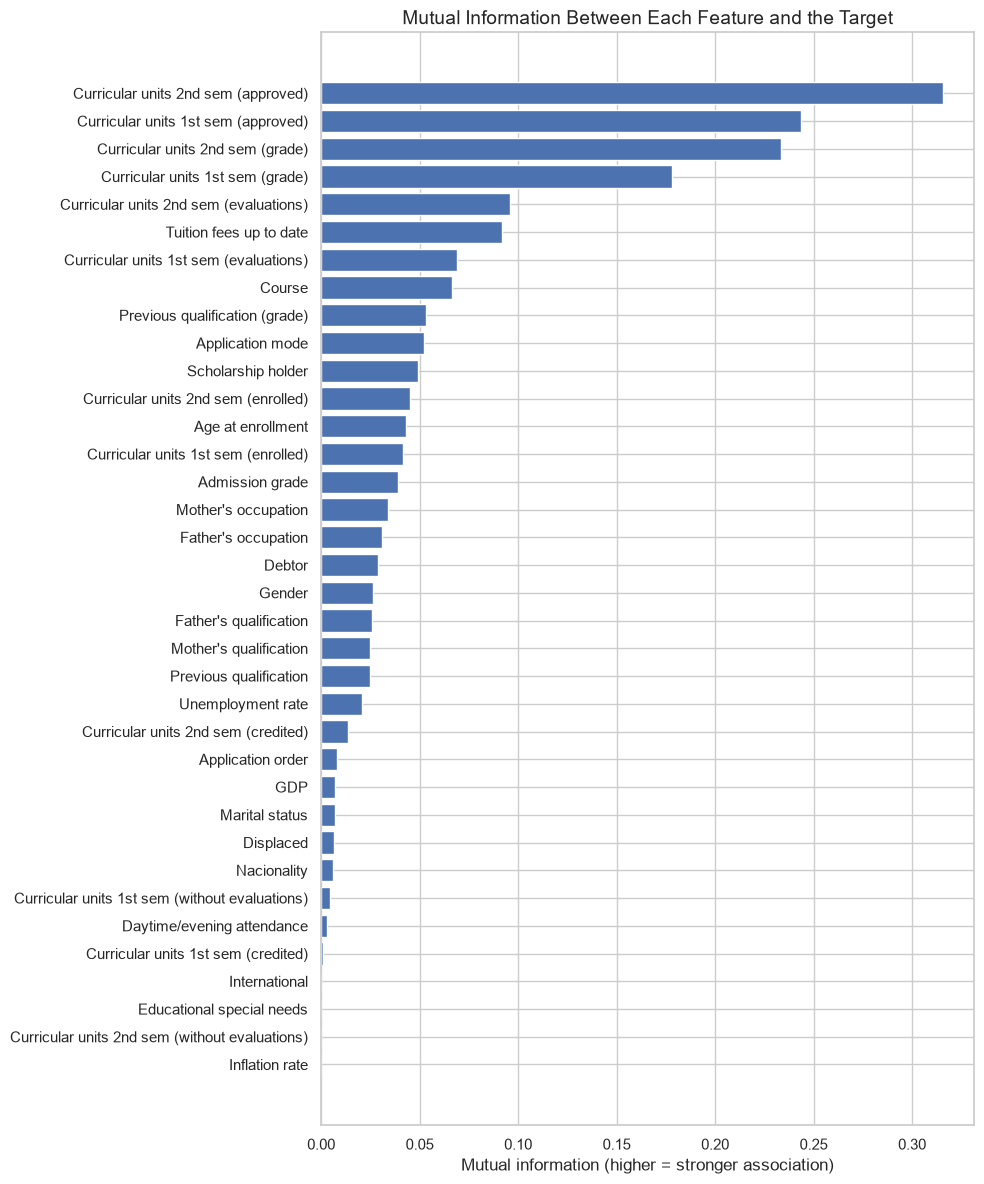

Curricular units 2nd sem (approved)       0.315642
Curricular units 1st sem (approved)       0.243411
Curricular units 2nd sem (grade)          0.233241
Curricular units 1st sem (grade)          0.177916
Curricular units 2nd sem (evaluations)    0.095685
Tuition fees up to date                   0.091828
Curricular units 1st sem (evaluations)    0.068761
Course                                    0.066468
Previous qualification (grade)            0.053209
Application mode                          0.052221
dtype: float64

In [13]:
from sklearn.feature_selection import mutual_info_classif

X_mi = df.drop(columns=["Target", "Target_label"])
y_mi = df["Target_label"]

# Columns that are binary or categorical codes are treated as discrete
discrete_mask = [col not in heatmap_features for col in X_mi.columns]

mi = mutual_info_classif(X_mi, y_mi, discrete_features=discrete_mask, random_state=42)
mi_scores = pd.Series(mi, index=X_mi.columns).sort_values()

plt.figure(figsize=(10, 12))
plt.barh(mi_scores.index, mi_scores.values, color="#4c72b0")
plt.title("Mutual Information Between Each Feature and the Target", fontsize=14)
plt.xlabel("Mutual information (higher = stronger association)")
plt.tight_layout()
plt.show()

mi_scores.sort_values(ascending=False).head(10)

**Observations:**
- The features with the highest mutual information are the **1st and 2nd semester approved units and grades**. They are followed by the semester **evaluations** features and **Tuition fees up to date**, which is the highest-ranked feature that does not depend on semester performance.
- Other features with noticeable scores include **Course**, **Application mode**, **Previous qualification (grade)**, and **Scholarship holder**.
- Features with mutual information close to zero show little individual association with the outcome in this analysis, although they may still contribute in combination with other features.

### 5. Binary Features vs. Target

For each binary feature, the chart shows the **percentage of students in each outcome class**. Comparing the bars within a chart shows whether the outcome distribution differs between the two groups of that feature.

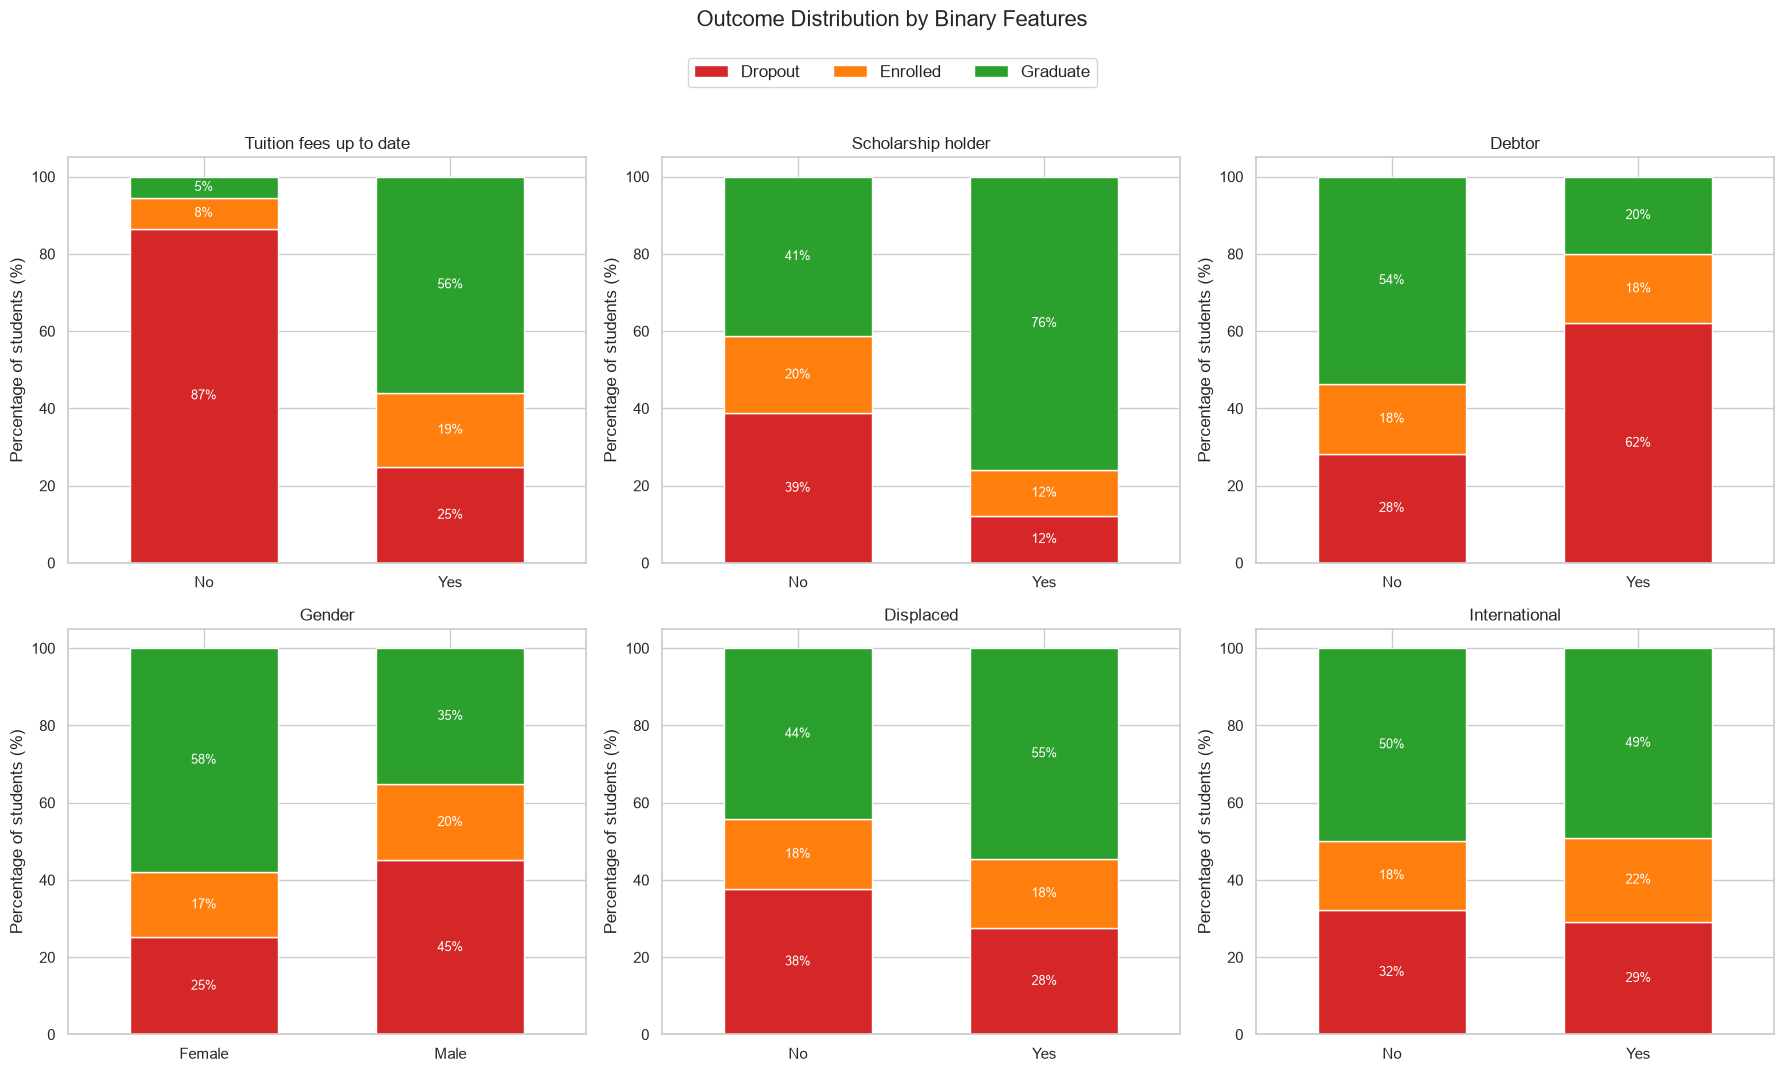

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (col, labels) in zip(axes.flat, binary_features.items()):
    ct = pd.crosstab(df[col].map(labels), df["Target_label"], normalize="index") * 100
    ct = ct[class_order]
    ct.plot(kind="bar", stacked=True, ax=ax,
            color=[palette[c] for c in class_order], width=0.6, legend=False)
    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Percentage of students (%)")
    ax.tick_params(axis="x", rotation=0)
    # Label each segment with its percentage
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f%%", label_type="center", fontsize=9, color="white")

handles, leg_labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, leg_labels, loc="upper center", ncol=3, fontsize=12, bbox_to_anchor=(0.5, 1.03))
fig.suptitle("Outcome Distribution by Binary Features", fontsize=16, y=1.07)
plt.tight_layout()
plt.show()

**Observations:**
- **Tuition fees up to date** shows the largest difference among the binary features. About 87% of students whose fees are **not** up to date dropped out, compared with about 25% of students who pay on time, so payment status is **associated with** dropout.
- **Scholarship holders** show a higher graduation rate (about 76% vs. 41%) and a lower dropout rate (about 12% vs. 39%) than non-holders.
- **Debtors** show a higher dropout rate than non-debtors (about 62% vs. 28%).
- **Male** students show a higher dropout rate than female students in this dataset (about 45% vs. 25%).
- **Displaced** students show a somewhat lower dropout rate than non-displaced students (about 28% vs. 38%).
- **International** status shows little difference, and only 110 students are international, so this comparison is less reliable.
- These are **associations**, not causes. For example, financial status may be linked to other factors (such as age or work commitments) that also affect outcomes.

### 6. Dropout Rate by Course

`Course` is a categorical code, so instead of a correlation we compare the dropout rate for each course directly. Course code meanings are listed on the UCI dataset page.

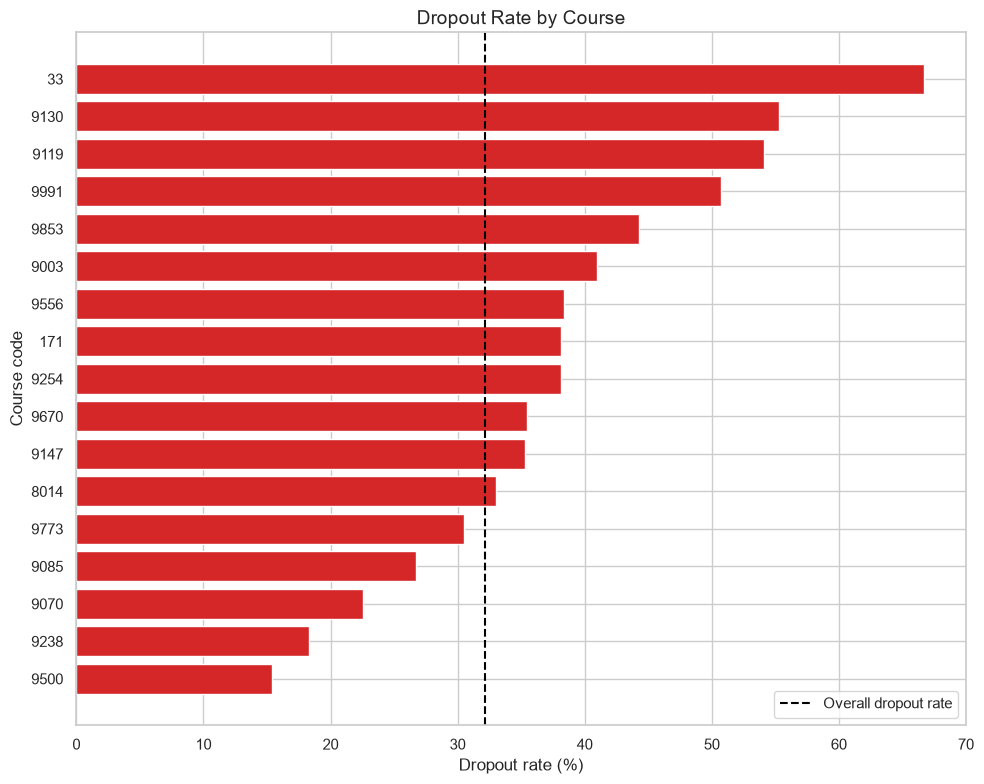

In [15]:
course_rates = (pd.crosstab(df["Course"], df["Target_label"], normalize="index")[class_order] * 100)
course_rates = course_rates.sort_values("Dropout")

plt.figure(figsize=(10, 8))
plt.barh(course_rates.index.astype(str), course_rates["Dropout"], color=palette["Dropout"])
plt.axvline((df["Target_label"] == "Dropout").mean() * 100, color="black",
            linestyle="--", label="Overall dropout rate")
plt.xlabel("Dropout rate (%)")
plt.ylabel("Course code")
plt.title("Dropout Rate by Course", fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

**Observations:**
- Dropout rates vary considerably between courses, from about 15% to about 67%, compared with an overall dropout rate of about 32% (dashed line).
- This suggests that the program of study is associated with dropout risk, so `Course` should be kept as a feature and **one-hot encoded** during preprocessing rather than used as a raw number.

### Summary of Relationship Insights

1. **1st and 2nd semester academic performance** (approved units and grades) shows the clearest association with the final outcome in the plots and the mutual information analysis.
2. **Financial features** (tuition fees status, scholarship, and debt) are associated with differences in dropout rates.
3. **Demographic features** such as age at enrollment and gender show moderate differences between outcome classes.
4. **Pre-university grades** and **macroeconomic indicators** show weaker associations.
5. The **1st and 2nd semester features are highly correlated with each other**, so the preprocessing step should address this redundancy.
6. The **Enrolled** class overlaps with both other classes in several plots. Whether it is actually the hardest class to predict will be verified with the evaluation results in Part B.

All findings in this section are **exploratory associations**. They do not establish cause and effect, and they do not show which features predict the outcome independently of the others.

### Note on Prediction Timing (Early Identification)

The features that show the strongest association with the outcome are the **1st and 2nd semester curricular unit features**. This information is **not available when a student first enrolls**. It only exists after the student has completed one or two semesters.

This affects what "early identification" can mean for our system:

| Prediction point | Features that can be used |
|---|---|
| **At enrollment** | Demographic, socioeconomic, application, and pre-university features, plus macroeconomic indicators for the enrollment year |
| **After the 1st semester** | All of the above, plus 1st semester curricular unit features |
| **After the 2nd semester** | All of the above, plus 2nd semester curricular unit features |

A model can only use the information available at the time the prediction is made. If the goal is to detect risk **before studies begin**, the semester features must be excluded. Including them would give results that look better than what the system could achieve in practice. The source also does not state exactly when some features (such as `Debtor` and `Tuition fees up to date`) were recorded, so their availability at each point should be confirmed.

**Decision:** Based on this analysis, the team decided to make predictions **after the 1st semester**. The model will use enrollment-time features and 1st semester curricular unit features (30 features in total), and the six 2nd semester features will be excluded. This gives academic advisors a full semester to intervene, keeps the grade information needed for the Phase 2 dashboard, and reduces the redundancy between the strongly correlated 1st and 2nd semester features.

## Preprocessing Pipeline

This section turns the raw data into a dataset ready for modeling. The prediction point is the end of the 1st semester, so only information available at that time is used. Each step is explained below.

### Step 1: Work on a copy and clean the column names

We work on a copy of the data so the original `df` used in the exploration above is not changed. Some column names contain hidden spaces or tabs, so they are cleaned to avoid errors later.

In [16]:
# Work on a copy so the original df (used by the EDA above) is not changed
data = df.drop(columns=["Target_label"], errors="ignore").copy()

# Remove hidden spaces/tabs from the column names (e.g. "Daytime/evening attendance\t")
data.columns = data.columns.str.strip()

print("Shape:", data.shape)
print("Columns with hidden whitespace left:", sum(c != c.strip() for c in data.columns))

Shape: (4424, 37)
Columns with hidden whitespace left: 0


### Step 2: Remove the 2nd semester features

The six 2nd semester features are removed because they do not exist yet at the end of the 1st semester. Using them would give the model future information (data leakage) and make the results look better than the system could achieve in practice. This leaves 30 features.

In [17]:
# Keep only information available at the end of the 1st semester
second_sem_cols = [c for c in data.columns if "2nd sem" in c]
print("Columns to drop:", len(second_sem_cols))
for c in second_sem_cols:
    print(" -", c)

data = data.drop(columns=second_sem_cols)
print("\nShape after dropping:", data.shape, "(30 features + Target)")

Columns to drop: 6
 - Curricular units 2nd sem (credited)
 - Curricular units 2nd sem (enrolled)
 - Curricular units 2nd sem (evaluations)
 - Curricular units 2nd sem (approved)
 - Curricular units 2nd sem (grade)
 - Curricular units 2nd sem (without evaluations)

Shape after dropping: (4424, 31) (30 features + Target)


### Step 3: Encode the target

The target is converted from text to numbers (0 = Dropout, 1 = Enrolled, 2 = Graduate) because machine learning models work with numbers. These numbers are only labels for the classes, not a scale.

In [18]:
# Convert the text target into numbers: 0 = Dropout, 1 = Enrolled, 2 = Graduate
target_codes = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
data["Target"] = data["Target"].map(target_codes)

print("Missing after mapping:", data["Target"].isna().sum())
print(data["Target"].value_counts().sort_index())

Missing after mapping: 0
Target
0    1421
1     794
2    2209
Name: count, dtype: int64


### Step 4: Create the academic progress feature

A new feature, `academic_progress`, is created as approved units divided by enrolled units in the 1st semester. It ranges from 0 (no units passed) to 1 (all units passed) and describes how far the student is progressing. Students who enrolled in 0 units would cause a division by zero, so their value is set to 0. This feature also supports the progress slider planned for the Phase 2 dashboard. The dataset has no real attendance column, so this feature measures academic progress, not attendance.

In [19]:
# Academic progress = approved units / enrolled units (1st semester)
enrolled = data["Curricular units 1st sem (enrolled)"]
approved = data["Curricular units 1st sem (approved)"]

# Divide only where enrolled > 0; students with 0 enrolled units get 0
data["academic_progress"] = (approved / enrolled.where(enrolled > 0)).fillna(0)

print("Lowest value:", data["academic_progress"].min())
print("Highest value:", data["academic_progress"].max())
print("Missing values:", data["academic_progress"].isna().sum())
print("\nAverage academic progress per outcome:")
print(data.groupby("Target")["academic_progress"].mean().round(2))

Lowest value: 0.0
Highest value: 1.0
Missing values: 0

Average academic progress per outcome:
Target
0    0.38
1    0.69
2    0.90
Name: academic_progress, dtype: float64


### Step 5: Flag students with no enrolled units

180 students enrolled in 0 units in the 1st semester. Their academic progress is set to 0, which is the same value as a student who enrolled in units but passed none. To keep the two groups apart, a yes/no feature `no_units_enrolled` is added. These students are not all dropouts (77 dropped out, 28 are still enrolled, and 75 graduated), so they are kept in the data and not removed.

In [20]:
# Flag students who enrolled in 0 units in the 1st semester (1 = yes, 0 = no)
data["no_units_enrolled"] = (enrolled == 0).astype(int)

print("Students with 0 enrolled units:", data["no_units_enrolled"].sum())
print("\nTheir outcomes (0 = Dropout, 1 = Enrolled, 2 = Graduate):")
print(data.loc[data["no_units_enrolled"] == 1, "Target"].value_counts().sort_index())
print("\nShape now:", data.shape)

Students with 0 enrolled units: 180

Their outcomes (0 = Dropout, 1 = Enrolled, 2 = Graduate):
Target
0    77
1    28
2    75
Name: count, dtype: int64

Shape now: (4424, 33)


### Step 6: Split into training and test sets

The data is split into 80% training (3,539 students) and 20% test (885 students). The split is done **before** any encoding or scaling, so the test students cannot influence how those steps are learned (this prevents data leakage). The split is stratified, meaning the Dropout, Enrolled, and Graduate proportions are the same in both parts, which matters because Enrolled is a small class. A fixed `random_state=42` makes the split reproducible, so every teammate gets exactly the same students in the test set. The test set is kept untouched until the final evaluation.

In [21]:
from sklearn.model_selection import train_test_split

# Separate the inputs (X) from the answer we want to predict (y)
X = data.drop(columns="Target")
y = data["Target"]

# 80% train / 20% test; stratify keeps the class proportions equal in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train students:", X_train.shape[0])
print("Test students: ", X_test.shape[0])
print("Number of features:", X.shape[1])

print("\nClass percentages (0 = Dropout, 1 = Enrolled, 2 = Graduate):")
summary = {
    "All data": y.value_counts(normalize=True).sort_index() * 100,
    "Train": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test": y_test.value_counts(normalize=True).sort_index() * 100,
}
import pandas as pd
print(pd.DataFrame(summary).round(1))

Train students: 3539
Test students:  885
Number of features: 32

Class percentages (0 = Dropout, 1 = Enrolled, 2 = Graduate):
        All data  Train  Test
Target                       
0           32.1   32.1  32.1
1           17.9   17.9  18.0
2           49.9   49.9  49.9


### Step 7: Group rare categories

Nine columns are stored as numbers but are really category codes with no real order: `Marital status`, `Application mode`, `Course`, `Previous qualification`, `Nacionality`, and the qualification and occupation of the mother and father. Some of them have many values that are used by only a handful of students (for example, 46 different father's occupations). Rare values add noise and would create many almost-empty columns, so any value used by less than 1% of the **training** students is grouped into one category, "Other" (coded -1). The rule is learned from the training data only and then applied to the test data. `Application order` is kept as a number because it is a preference rank (1st choice, 2nd choice, ...), so it does have an order.

In [22]:
# Columns that are stored as numbers but are really category codes (no real order)
category_cols = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]

# Work on copies of the train and test inputs
X_train = X_train.copy()
X_test = X_test.copy()

# Group rare categories: a value used by less than 1% of TRAINING students becomes -1 ("Other")
for col in category_cols:
    share = X_train[col].value_counts(normalize=True)
    frequent = share[share >= 0.01].index
    before = X_train[col].nunique()
    X_train[col] = X_train[col].where(X_train[col].isin(frequent), -1)
    X_test[col] = X_test[col].where(X_test[col].isin(frequent), -1)
    print(f"{col:25s} {before:2d} values -> {X_train[col].nunique():2d} values")

Marital status             6 values ->  4 values
Application mode          18 values -> 10 values
Course                    17 values -> 17 values
Previous qualification    17 values ->  5 values
Nacionality               19 values ->  2 values
Mother's qualification    28 values ->  9 values
Father's qualification    32 values ->  8 values
Mother's occupation       31 values -> 11 values
Father's occupation       41 values -> 13 values


### Step 8: One-hot encode the categories

Each category column is replaced by 0/1 columns, one per category (one-hot encoding). For example, `Course` becomes columns such as `Course_9500`, where 1 means the student is in that course. This prevents the model from treating the codes as quantities, for example thinking that course 9500 is "bigger" than course 33. The encoder learns the categories from the training data only. Any value it has not seen is encoded as all zeros in the test data instead of causing an error.

In [23]:
from sklearn.preprocessing import OneHotEncoder

# Learn the categories from the training data only, then apply to both parts
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
train_encoded = encoder.fit_transform(X_train[category_cols])
test_encoded = encoder.transform(X_test[category_cols])
new_names = encoder.get_feature_names_out(category_cols)

# Replace the original category columns with the new 0/1 columns
X_train = pd.concat(
    [X_train.drop(columns=category_cols),
     pd.DataFrame(train_encoded, columns=new_names, index=X_train.index)], axis=1)
X_test = pd.concat(
    [X_test.drop(columns=category_cols),
     pd.DataFrame(test_encoded, columns=new_names, index=X_test.index)], axis=1)

print("Columns before encoding:", X.shape[1])
print("Columns after encoding: ", X_train.shape[1])
print("Train and test have the same columns:", list(X_train.columns) == list(X_test.columns))
print("Missing values:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

Columns before encoding: 32
Columns after encoding:  102
Train and test have the same columns: True
Missing values: 0


### Step 9: Scale the numeric features

The numeric features have very different ranges. For example, age goes from 17 to 70, admission grade from 95 to 190, and unit counts from 0 to 20. Scaling puts them on a similar range (average 0, spread 1, called standardization) so that no feature dominates just because its numbers are larger. This matters most for distance-based models such as SVM, and it does not harm tree-based models. The scaler learns the average and spread from the **training** data only and then applies the same values to the test data, so no test information leaks in. The 0/1 columns and `academic_progress` (already between 0 and 1) are not scaled.

In [24]:
from sklearn.preprocessing import StandardScaler

# Numeric columns that have different ranges (age, grades, unit counts, economy)
numeric_cols = [
    "Age at enrollment", "Admission grade", "Previous qualification (grade)",
    "Application order",
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
    "Unemployment rate", "Inflation rate", "GDP",
]

print("Before scaling (training data):")
print(X_train[numeric_cols].agg(["min", "max"]).T.round(1).head(5))

# Learn the average and spread from the TRAINING data only, then apply to both parts
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("\nAfter scaling - average and spread of the first 5 columns:")
check = pd.DataFrame({
    "train mean": X_train[numeric_cols].mean(),
    "train std": X_train[numeric_cols].std(),
    "test mean": X_test[numeric_cols].mean(),
}).round(2)
print(check.head(5))

Before scaling (training data):
                                      min    max
Age at enrollment                    17.0   70.0
Admission grade                      95.0  190.0
Previous qualification (grade)       95.0  190.0
Application order                     0.0    9.0
Curricular units 1st sem (credited)   0.0   20.0

After scaling - average and spread of the first 5 columns:
                                     train mean  train std  test mean
Age at enrollment                           0.0        1.0       0.01
Admission grade                            -0.0        1.0       0.03
Previous qualification (grade)              0.0        1.0      -0.03
Application order                          -0.0        1.0       0.00
Curricular units 1st sem (credited)        -0.0        1.0      -0.02


### Step 10: Handle class imbalance with class weights

Graduate is about half of the data, while Enrolled is only about 18%. Without correction, a model could ignore Enrolled and still look accurate. Instead of creating synthetic students (SMOTE), we use **class weights**: during training, mistakes on rarer classes count more. The weights are computed from the training data only. They do not change the dataset, so they are not stored in the file. Models use them with `class_weight="balanced"`, or by passing the weights printed below.

In [25]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1, 2])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)

print("Class weights (computed from the training data):")
for name, w in zip(["Dropout (0)", "Enrolled (1)", "Graduate (2)"], weights):
    print(f"  {name:13s} {w:.2f}")

Class weights (computed from the training data):
  Dropout (0)   1.04
  Enrolled (1)  1.86
  Graduate (2)  0.67


## Preprocessed Dataset Ready for Modeling

All preprocessing steps are complete. The final dataset is saved as `Dataset/preprocessed_data.csv`. It contains one row per student (4,424 rows) and 104 columns: 102 numeric features, the `Target` column (0 = Dropout, 1 = Enrolled, 2 = Graduate), and a `split` column that marks each student as `train` (3,539 students) or `test` (885 students). All team members must use this same split so that model results are comparable.

In [26]:
from pathlib import Path

# Put train and test back together, with a column that says which part each student belongs to
train_part = X_train.assign(Target=y_train, split="train")
test_part = X_test.assign(Target=y_test, split="test")
preprocessed = pd.concat([train_part, test_part]).sort_index()   # keep the original student order

# Save to the Dataset folder
output_path = Path("Dataset/preprocessed_data.csv")
output_path.parent.mkdir(exist_ok=True)
preprocessed.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Shape:", preprocessed.shape, "(102 features + Target + split)")
print(preprocessed["split"].value_counts())

Saved: Dataset\preprocessed_data.csv
Shape: (4424, 104) (102 features + Target + split)
split
train    3539
test      885
Name: count, dtype: int64


In [27]:
# Reload the saved file to make sure it is correct
check = pd.read_csv("Dataset/preprocessed_data.csv")
print("Shape after reloading:", check.shape)
print("Missing values:", check.isna().sum().sum())
print("Non-numeric columns (should be only 'split'):", list(check.select_dtypes(exclude="number").columns))
print("\nTarget counts (0 = Dropout, 1 = Enrolled, 2 = Graduate):")
print(check["Target"].value_counts().sort_index())

Shape after reloading: (4424, 104)
Missing values: 0
Non-numeric columns (should be only 'split'): ['split']

Target counts (0 = Dropout, 1 = Enrolled, 2 = Graduate):
Target
0    1421
1     794
2    2209
Name: count, dtype: int64


### How to load the dataset for modeling

Use the `split` column to get the shared train/test split:

    data = pd.read_csv("Dataset/preprocessed_data.csv")
    train = data[data["split"] == "train"]
    test = data[data["split"] == "test"]

    X_train = train.drop(columns=["Target", "split"])
    y_train = train["Target"]
    X_test = test.drop(columns=["Target", "split"])
    y_test = test["Target"]

Class imbalance is handled during training with class weights (for example `class_weight="balanced"`).

## Key Insights & Challenges

### Key Insights

1. **Dataset completeness:** The dataset contains 4,424 student records, 36 input features, and one target column. No missing values were found, so missing-value imputation is not required for the original dataset.

2. **Class imbalance:** Graduate is the largest class (49.9%), followed by Dropout (32.1%) and Enrolled (17.9%). Because of this imbalance, accuracy alone is not sufficient, and the models should also be evaluated using per-class precision, recall, and F1-score.

3. **Semester academic performance:** Academic performance during the first and second semesters shows the strongest associations with student outcomes. For example, the median number of approved units in the second semester is 0 for Dropout, 4 for Enrolled, and 6 for Graduate. Semester performance features also rank among the most informative variables in the mutual information analysis.

4. **Financial attributes:** Financial indicators show substantial differences in dropout rates:
   - Approximately 87% of students whose tuition fees were not up to date dropped out, compared with 25% of students whose fees were up to date.
   - Scholarship holders had a lower dropout rate than non-scholarship holders (12% versus 39%).
   - Debtors had a higher dropout rate than non-debtors (62% versus 28%).

5. **Demographic and course differences:** Students who dropped out were generally older at enrollment, with a median age of 23 compared with 19 for graduates. Male students had a higher observed dropout rate than female students (45% versus 25%). Dropout rates also varied across courses, ranging from approximately 15% to 67%.

6. **Weaker associations:** Pre-university grades and macroeconomic indicators generally showed weaker individual associations with student outcomes than semester academic performance.

These findings describe associations observed during exploratory analysis and do not establish cause-and-effect relationships.

### Challenges

1. **Categorical codes stored as numbers:** Several variables, including `Course`, `Marital status`, `Application mode`, and `Nacionality`, are stored as integers but represent categories. These variables must be identified correctly to avoid interpreting their numerical codes as continuous measurements.

2. **Measuring association with a multi-class target:** The `Target` column contains three categories. Pearson correlation with arbitrary numerical class labels would be misleading, so the exploration used box plots, class proportions, and mutual information to examine relationships with student outcomes.

3. **Correlated semester features:** Corresponding first- and second-semester features are strongly correlated, including credited units (approximately 0.95), enrolled units (0.94), approved units (0.90), and grades (0.84). This redundancy was resolved in preprocessing by removing the six second-semester features, which also were not available at the chosen prediction point.

4. **Class imbalance and overlap:** Enrolled is the smallest class, and its feature distributions overlap with those of the other classes. This may make classification more challenging and highlights the importance of evaluating performance separately for each class.

5. **Prediction timing and data leakage:** Semester performance features are not available when a student first enrolls. To support early intervention while using academic performance information, the team decided to make predictions after the first semester. The model will use enrollment-time and first-semester features only, excluding all six second-semester features. The availability of financial and other status variables at the prediction point should also be verified.

6. **Zero values in semester grades:** Approximately 16% of students have a first-semester grade of zero, and 20% have a second-semester grade of zero. In this dataset, zero grades coincide with zero approved units. However, 369 students in the first semester and 469 students in the second semester have zero grades despite having recorded evaluations. Therefore, a zero grade does not necessarily mean that a student was not evaluated. These values were retained, and their interpretation requires further verification before treating them as missing values or errors.

7. **File formatting issues:** The dataset uses semicolons (`;`) as separators. The original column name `Daytime/evening attendance` contains a trailing tab character, and `Nacionality` follows the spelling used in the source dataset. These details require careful handling when loading and referencing the columns.

8. **Students with no enrolled units:** 180 students enrolled in zero units in the first semester, so their academic progress (approved ÷ enrolled) cannot be calculated. It was set to 0, and a separate indicator, `no_units_enrolled`, was added so the model can distinguish them from students who enrolled but passed nothing. These students are not all dropouts (77 dropped out, 28 are still enrolled, and 75 graduated), so they were kept.

9. **High-cardinality categories:** Some category columns have many values used by very few students (for example, 46 different father's occupations). Values used by less than 1% of the training students were grouped into "Other" before one-hot encoding. Even so, encoding raised the number of features from 32 to 102.

10. **No real attendance data:** The dataset has no attendance column (`Daytime/evening attendance` only describes the class schedule). The Phase 2 dashboard will use academic progress (approved ÷ enrolled units) instead of attendance.

11. **Avoiding data leakage:** The data was split into train and test before grouping, encoding, and scaling, and all of these were learned from the training data only.